# Online Non-Negative Matrix Factorization using Hebbian/Anti-Hebbian network

A third-party reimplementation of the paper: "A Hebbian/Anti-Hebbian Network Derived from Online Non-Negative Matrix Factorization Can Cluster and Discover Sparse Features"
https://arxiv.org/abs/1503.00680

In [1]:
import matlab.engine

In [2]:
eng = matlab.engine.start_matlab()

s = eng.genpath("/home/kushal/repos/NMFLibrary/")
eng.addpath(s, nargout=0)

In [3]:
import numpy as np
import fastplotlib as fpl
import matplotlib.pyplot as plt
%matplotlib inline
import random

WGPU: enumerate_adapters() is deprecated, use enumerate_adapters_sync() instead.
WGPU: request_adapter() is deprecated, use request_adapter_sync() instead.


Image(value=b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR\x00\x00\x01,\x00\x00\x007\x08\x06\x00\x00\x00\xb6\x1bw\x99\x…

Valid,Device,Type,Backend,Driver
✅ (default),AMD Radeon Graphics (RADV GFX1103_R1),IntegratedGPU,Vulkan,Mesa 22.3.6
❗ limited,"llvmpipe (LLVM 15.0.6, 256 bits)",CPU,Vulkan,Mesa 22.3.6 (LLVM 15.0.6)
❌,"AMD Radeon Graphics (gfx1103_r1, LLVM 15.0.6, DRM 3.49, 6.1.0-28-amd64)",Unknown,OpenGL,4.6 (Core Profile) Mesa 22.3.6


To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.


## Dataset
First prepare the dataset for clustering.

In [4]:
def generate_data(
        n_timepoints: int,
        n_components: int,
        noise: int,
        n_pixels: int | tuple[int, int],  # n_pixels PER component, if a tuple a random number of pixles within the range is used
        n_pixels_bg,
        interp_factor: int = 2,
        firing_prop: float = 0.1,
) -> tuple[np.ndarray, np.ndarray]:
    """

    Parameters
    ----------
    n_timepoints: int

    n_components: int

    noise: int

    n_pixels: int, or (min, max) range
        n_pixels PER components, if (min, max) range is given then a random number of pixels within this range
        is used for each component

    n_pixels_bg: int

    interp_factor: int
        interpolation factor

    Returns
    -------
    np.ndarray, np.ndarray
        data [pixels, n_timepoints * interp_factor], truth labels: 1D array 0 is background

    """

    clean = np.zeros((n_components, n_timepoints * interp_factor))

    x = 0
    a = 0.7

    b = 0

    spikes = list()

    for i in range(n_components):
        spikes.append((np.random.rand(n_timepoints) < firing_prop).astype(float))

    for c_ix in range(n_components):
        for i in range(2, n_timepoints):
            clean[c_ix, i] = (a * clean[c_ix, i - 1]) + (b * clean[c_ix, i - 2]) + (50 * spikes[c_ix][i])

        x_ = np.arange(0, n_timepoints * interp_factor)
        xp_ = np.linspace(0, n_timepoints * interp_factor, n_timepoints)
        clean[c_ix] = np.interp(x_, xp_, fp=clean[c_ix, :n_timepoints])

    n_timepoints *= interp_factor

    series = list()
    labels = list()

    for i in range(n_components):
        # determine number of pixels for this component
        if isinstance(n_pixels, int):
            _n_pixels_iter = n_pixels
        elif isinstance(n_pixels, tuple):
            _n_pixels_iter = np.random.randint(low=n_pixels[0], high=n_pixels[1])

        for j in range(_n_pixels_iter):
            series.append(clean[i] + np.random.normal(scale=noise, size=n_timepoints))
            labels.append(i + 1)

    # series = np.vstack(series)

    bg_pixels = [np.random.normal(scale=noise, size=n_timepoints) for i in range(n_pixels_bg)]
    series = np.vstack([*series, *bg_pixels])
    labels = np.array([*labels, *[0 for i in range(len(bg_pixels))]])

    return series, labels

## Training

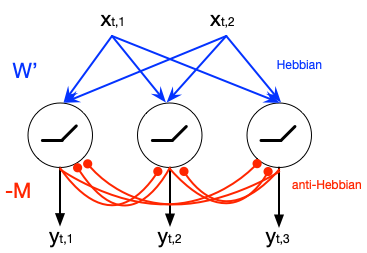

Activation of the output node is,

$$
y_{T,i} = ReLU(W_{T,i} x_T - M_{T,i} y_T)
$$

Weight update rule is

$$
\hat{Y}_{T,i} = \hat{Y}_{T-1,i} + y^2_{T-1,i} 
$$

$$
W_{T,i,j} = W_{T-1,i,j} + \frac{y_{T-1,i} \left( x_{T-1,j} - W_{T-1,i,j} y_{T-1,i} \right)} {\hat{Y}_{T,i}} 
$$

$$
M_{T,i,j\ne i} = M_{T-1,i,j} + \frac{y_{T-1,i} \left( y_{T-1,j} - M_{T-1,i,j} y_{T-1,i}  \right) } { \hat{Y}_{T,i} }
$$

In [5]:
def update_weight(W, M, x_t, y_t, y_hat):
    """ Update weight matrix of W and M.
    Equation (8) in the original paper.
    """
    y_dim = y_t.shape[0]
    y_hat += (y_t * y_t)
    
    # (3,1) x (1,2) = (3,2)
    dW = y_t[:,np.newaxis].dot( x_t[np.newaxis,:] - (W.T.dot(y_t[:,np.newaxis])).T)
    #dW = dW / y_hat[:,np.newaxis]
    # (3, 2)
    
    for i in range(y_dim):
        if y_hat[i] > 0:
            W[i] += (dW[i] / y_hat[i])
    
    # (3,1) x (1,3) = (3,3)
    dM = y_t[:,np.newaxis].dot( y_t[np.newaxis,:] - (M.T.dot(y_t[:,np.newaxis])).T)
    #dM = dM / y_hat[:,np.newaxis]
    
    # Set diagonal elements to zero
    for i in range(M.shape[0]):
        dM[i,i] = 0.0
    
    for i in range(y_dim):
        if y_hat[i] > 0:
            M[i] += (dM[i] / y_hat[i])

If the i-th degree of freedom has not been utilized, then adjust the output.

$$
y_{Ti} = \left\{
\begin{array}{l}
0, \quad\left(\left\|x_{T}\right\|^{2}_2-\sum_{k=1, k \neq i}^{m} y_{Tk}^{2}\right)^{2} \leq \lambda \\
\left(\left\|x_{T}\right\|^{2}_2-\sum_{k=1, k \neq i}^{m} y_{Tk}^{2}\right)^{1 / 2}, \left(\left\|x_{T}\right\|^{2}_2-\sum_{k=1, k \neq i}^{m} y_{Tk}^{2}\right)^{2}>\lambda
\end{array}
\right.
$$

In [6]:
def adjust_y_i(y_t, x_t, y_index, lambd=0.5):
    """ If the node in y_t is not active previously, adjust it.
    Equation (5) in the original paper.
    """
    # y_t = (3,)
    # x_t = (2,)
    
    y_dim = y_t.shape[0]
    
    # Calculate squree L2 norm of x_t
    x_norm_sq = x_t.dot(x_t)    
    y_t_sqs = y_t * y_t # (3,)
    
    y_t_adj = np.empty_like(y_t)
    
    d_i = x_norm_sq - (np.sum(y_t_sqs) - y_t_sqs[y_index])
    d_i_sq = d_i * d_i
    if d_i_sq <= lambd:
        return 0.0
    else:
        if d_i < 0.0:
            print("d_i was negative: {}".format(d_i))
            d_i = 0.0
    return np.sqrt(d_i)

In [7]:
from tqdm import tqdm

In [8]:
import seaborn as sns

In [9]:
results = list()

for n_components in range(2, 8):
    np.random.seed(0)
    X, _ = generate_data(
        n_timepoints=5_000,
        n_components=n_components,
        noise=5,
        n_pixels=5,
        n_pixels_bg=0,
        interp_factor=1,
        firing_prop=0.05,
    )

    result = {
        "X": None,
        "W": None,
        "M": None,
        "Y": None
    }
    
    X = X.T

    x_dim = X.shape[1] # 2
    T = X.shape[0] # 300
    y_dim = n_components

    W = np.zeros([y_dim, x_dim]) # (3, 2)
    M = np.zeros([y_dim, y_dim]) # (3, 3)
    
    # Active set {i}
    active_i_s = []
    active_counts = np.zeros([y_dim], dtype=np.int32)
    
    # Iteration count for convergence
    iteration = 1_000
    
    y_t_sum = np.zeros([y_dim])
    y_hat = np.zeros([y_dim]) # 3
    
    clusters = []
    
    for t in tqdm(range(T)):
        # Get one input sample x_t
        x_t = X[t].copy() # (2,)
    
        # x_t -= np.mean(x_t)
        
        # Zero initialze y_t
        y_t = np.zeros(y_dim)
        for i in active_i_s:
            # If 'i' is in the active set {i}
            for it in range(iteration):
                # W[i] = (2,)
                # M[i] = (3,)
                a = W[i].dot(x_t) - M[i].dot(y_t)
                # a is scaler
                y_t_i = max(0, a)
            y_t[i] = y_t_i
        
        for i in range(y_dim):
            if active_counts[i] == 0:
                y_t[i] = adjust_y_i(y_t, x_t, i)
                    
        for i in range(y_dim):
            if y_t[i] != 0.0:
                active_counts[i] += 1
                
        for i in range(y_dim):
            if (i not in active_i_s) and active_counts[i] > 0:
                active_i_s.append(i)
    
        update_weight(W, M, x_t, y_t, y_hat)
        
        # cluster = np.argmax(y_t)
        clusters.append(y_t)
        
    result["X"] = X.copy()
    result["Y"] = np.vstack(clusters)
    result["W"] = W.copy()
    result["M"] = M.copy()

    results.append(result)

  1%|▌                                                                                                        | 26/5000 [00:00<00:19, 256.24it/s]

d_i was negative: -104714.48636261479


  0%|▍                                                                                                        | 23/5000 [00:00<00:22, 223.56it/s]

d_i was negative: -14236.028273939883
d_i was negative: -14236.028273939883


  0%|▍                                                                                                        | 19/5000 [00:00<00:27, 180.97it/s]

d_i was negative: -105640.64049364903
d_i was negative: -105640.64049364903
d_i was negative: -105640.64049364903


100%|███████████████████████████████████████████████████████████████████████████████████████████████████████| 5000/5000 [00:32<00:00, 156.05it/s]


# Example of $X^T$, $P(firing)$ = 0.05

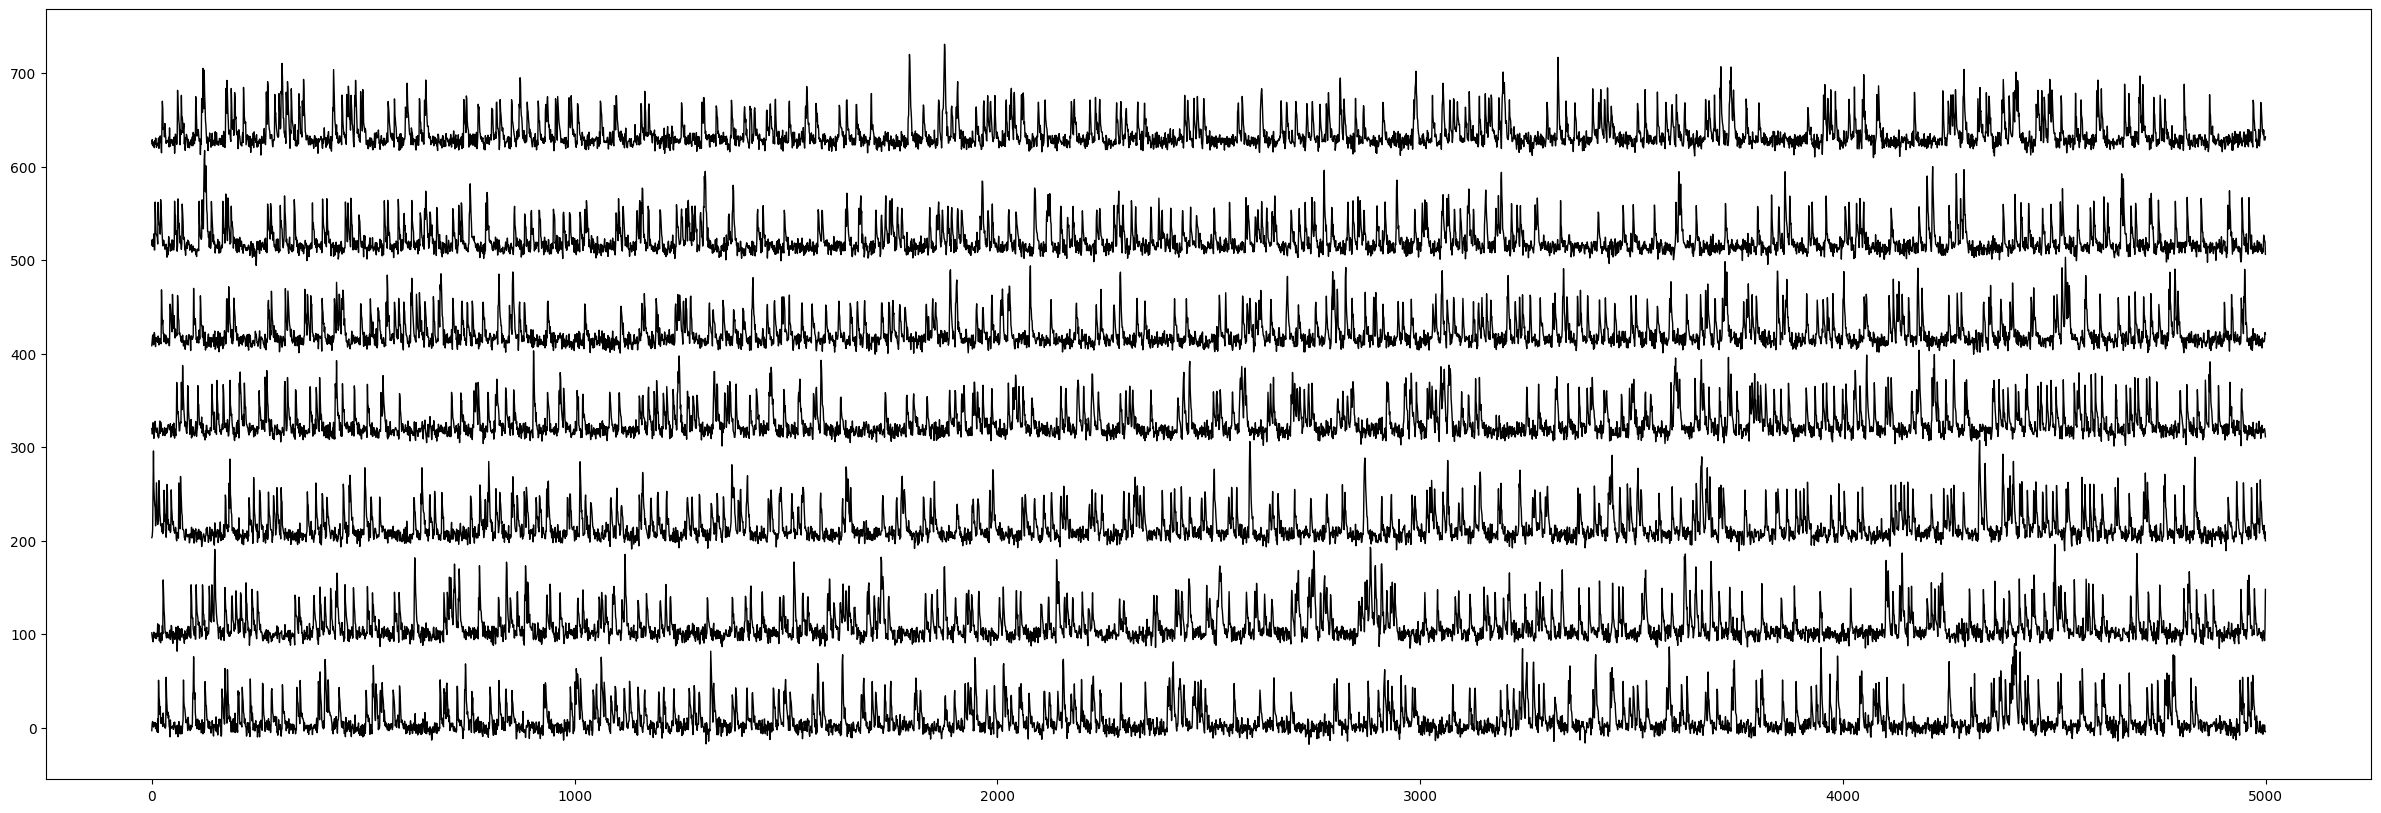

In [11]:
plt.figure(figsize=(30, 10))
separation = 0
for i, x in enumerate(results[5]["X"].T[::5]):
    plt.plot(x + separation, linewidth=1, c="k")
    separation = x.max() + separation + 10

# W 

RFBOutputContext()

WGPU: request_device() is deprecated, use request_device_sync() instead.
/home/kushal/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:18: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


JupyterWgpuCanvas()
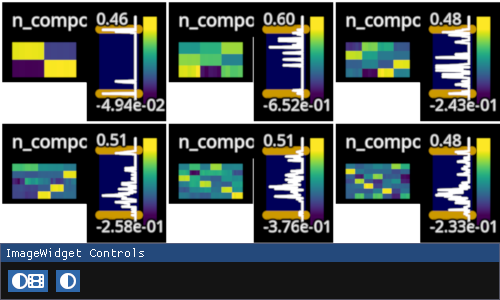

In [12]:
fpl.ImageWidget(
    [r["W"] for r in results],
    cmap="viridis",
    figure_kwargs={"controller_ids": None},
    names=[f"n_components: {i}" for i in range(2, 8)]
).show(maintain_aspect=False)

# M

RFBOutputContext()

JupyterWgpuCanvas()
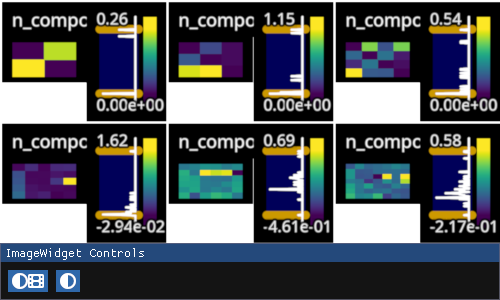

In [13]:
fpl.ImageWidget(
    [r["M"] for r in results],
    cmap="viridis",
    figure_kwargs={"controller_ids": None},
    names=[f"n_components: {i}" for i in range(2, 8)]
).show(maintain_aspect=False)

# Y

RFBOutputContext()

JupyterWgpuCanvas()
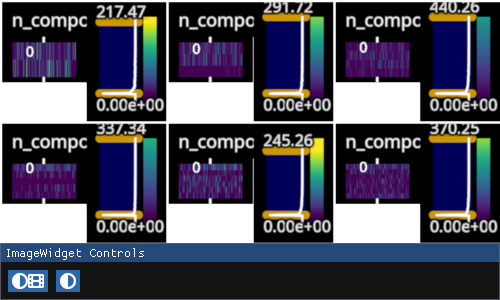

In [14]:
fpl.ImageWidget(
    [r["Y"].T for r in results],
    cmap="viridis",
    figure_kwargs={"controller_ids": None},
    names=[f"n_components: {i}" for i in range(2, 8)]
).show(maintain_aspect=False)

# X

RFBOutputContext()

JupyterWgpuCanvas()
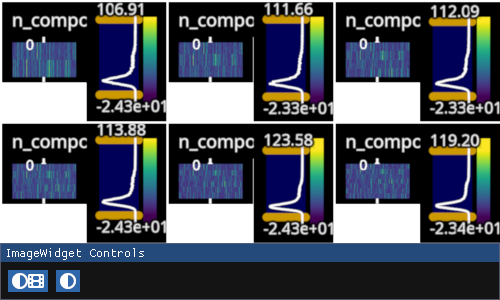

In [15]:
fpl.ImageWidget(
    [r["X"].T for r in results],
    cmap="viridis",
    figure_kwargs={"controller_ids": None},
    names=[f"n_components: {i}" for i in range(2, 8)]
).show(maintain_aspect=False)

# Comparison of $X$ and $Y$

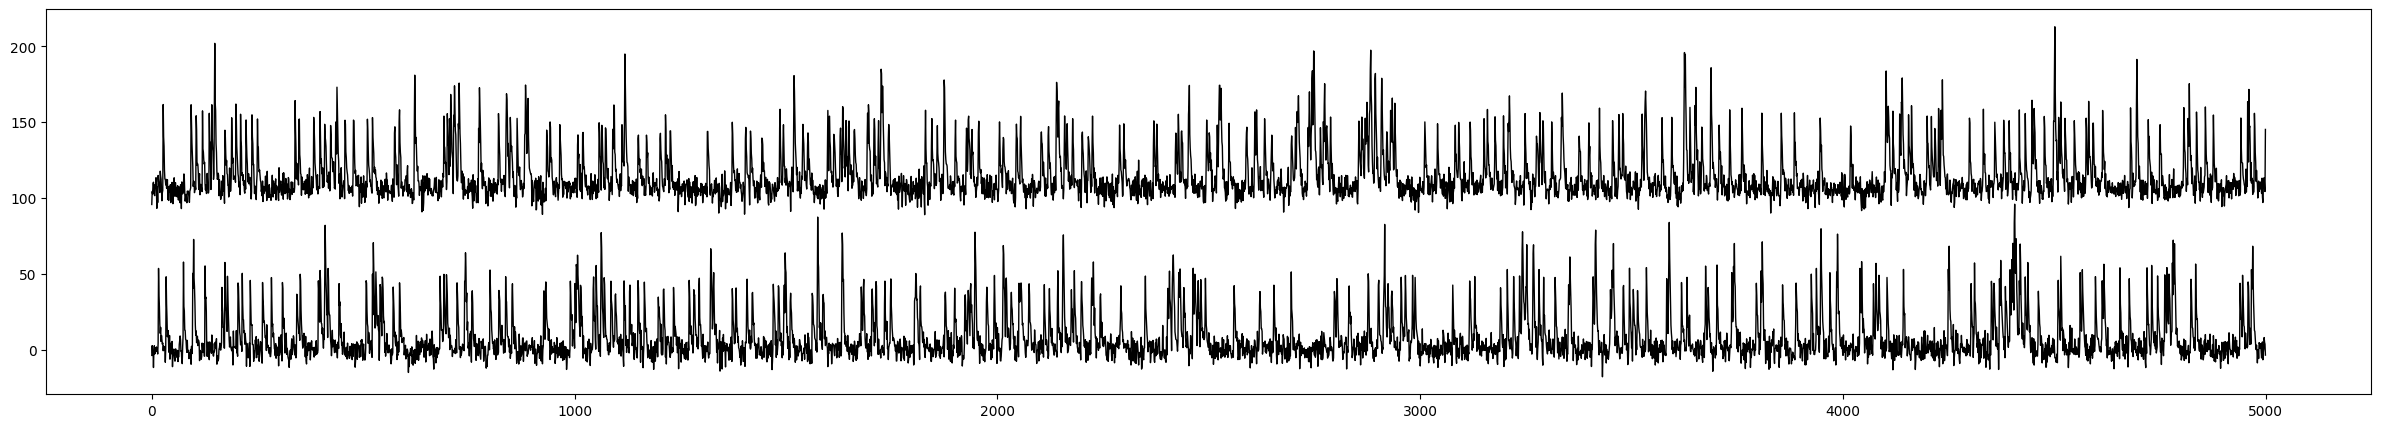

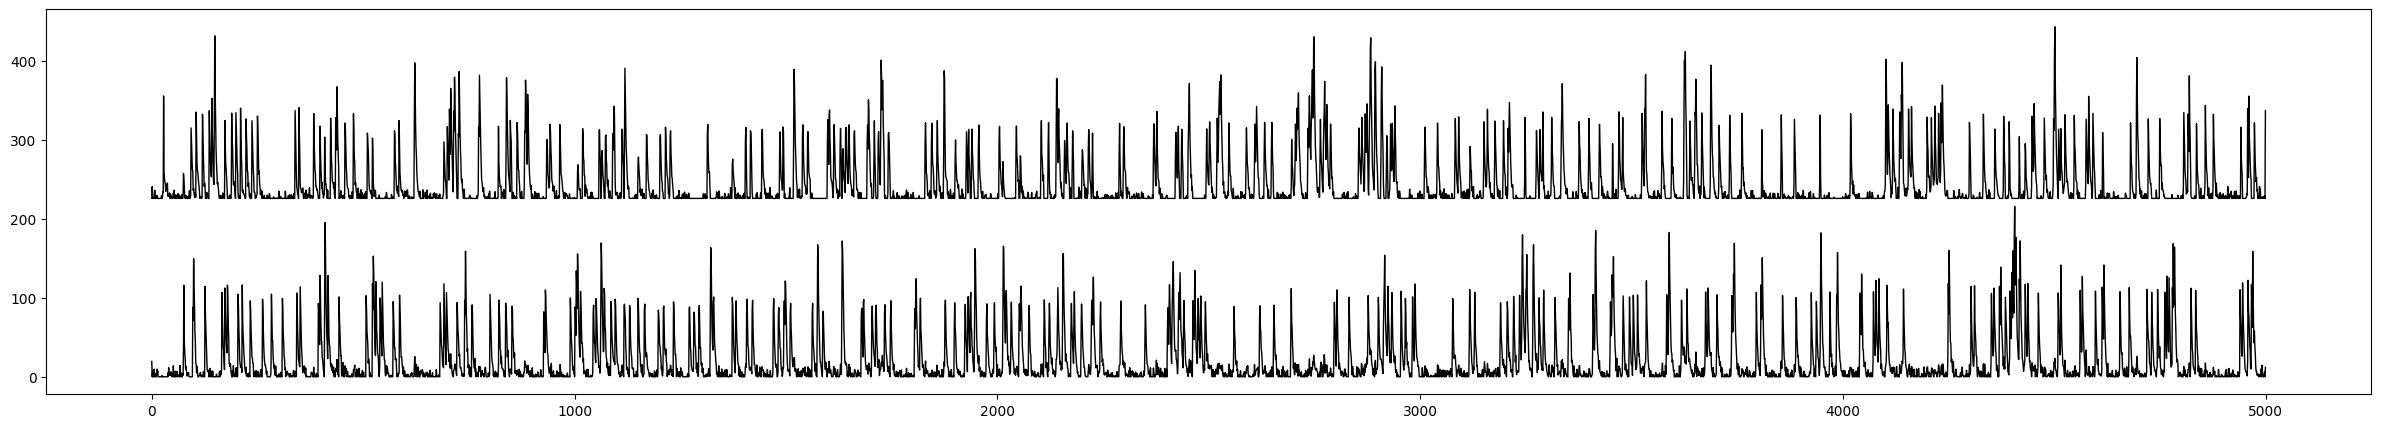

In [16]:
n = 0

plt.figure(figsize=(30, 5))

separation = 0
for i, x in enumerate(results[n]["X"].T[::5]):
    plt.plot(x + separation, linewidth=1, c="k")
    separation = x.max() + separation + 10

plt.show()

plt.figure(figsize=(30, 5))

separation = 0
for i, y in enumerate(results[n]["Y"].T):
    plt.plot(y + separation, linewidth=1, c="k")
    separation = y.max() + separation + 10

plt.show()

In [17]:
from numba import guvectorize, float64, int64, float32, prange, njit
from itertools import product

In [18]:
@njit(parallel=True)
def get_corr(
    i: int,
    Y: np.ndarray,
    dists: np.ndarray,
):
    for j in prange(Y.shape[0]):
        u = Y[i]
        v = Y[j]

        corr = (u.T @ v) / (np.linalg.norm(u, ord=2) * np.linalg.norm(v, ord=2))

        corr = max(corr, 0)

        dists[j] = corr

In [19]:
snmf_results = list()

for r in results:
    snmf_result = {"W": None}
    
    X = r["X"]
    snmf_result["X"] = X

    corr_mat = np.zeros((X.T.shape[0], X.T.shape[0]), dtype=np.float32)

    for i in tqdm(range(X.T.shape[0])):
        output_matrix = np.zeros((X.T.shape[0],))
        get_corr(
            i,
            X.T,
            output_matrix,
        )
        corr_mat[i] = output_matrix**2

    W = np.asarray(eng.symm_anls(corr_mat, float(r["Y"].shape[1]))["W"])
    snmf_result["W"] = W
    W_sorted = W[np.argsort(np.argmax(W, axis=1))]
    snmf_result["W_sorted"] = W_sorted
    snmf_result["Y"] = W_sorted.T @ X.T

    snmf_results.append(snmf_result)

  0%|                                                                                                                     | 0/10 [00:00<?, ?it/s]/tmp/ipykernel_210808/859116307.py:11: NumbaPerformanceWarning: '@' is faster on contiguous arrays, called on (Array(float64, 1, 'A', False, aligned=True), Array(float64, 1, 'A', False, aligned=True))
  corr = (u.T @ v) / (np.linalg.norm(u, ord=2) * np.linalg.norm(v, ord=2))
/tmp/ipykernel_210808/859116307.py:11: NumbaPerformanceWarning: '@' is faster on contiguous arrays, called on (Array(float64, 1, 'A', False, aligned=True), Array(float64, 1, 'A', False, aligned=True))
  corr = (u.T @ v) / (np.linalg.norm(u, ord=2) * np.linalg.norm(v, ord=2))
100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████| 35/35 [00:00<00:00, 8223.20it/s]


# SymmNMF Results

RFBOutputContext()

/home/kushal/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:18: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


JupyterWgpuCanvas()
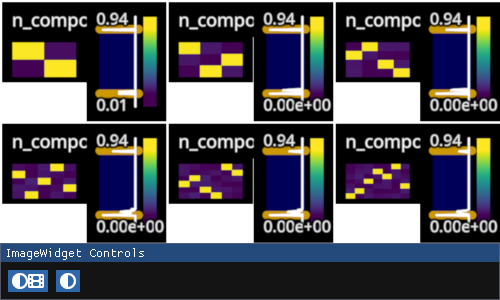

In [20]:
fpl.ImageWidget(
    [r["W"] for r in snmf_results],
    cmap="viridis",
    figure_kwargs={"controller_ids": None},
    names=[f"n_components: {i}" for i in range(2, 8)]
).show(maintain_aspect=False)

# Comparison of $X$ and $Y$ for `n_components = 3`

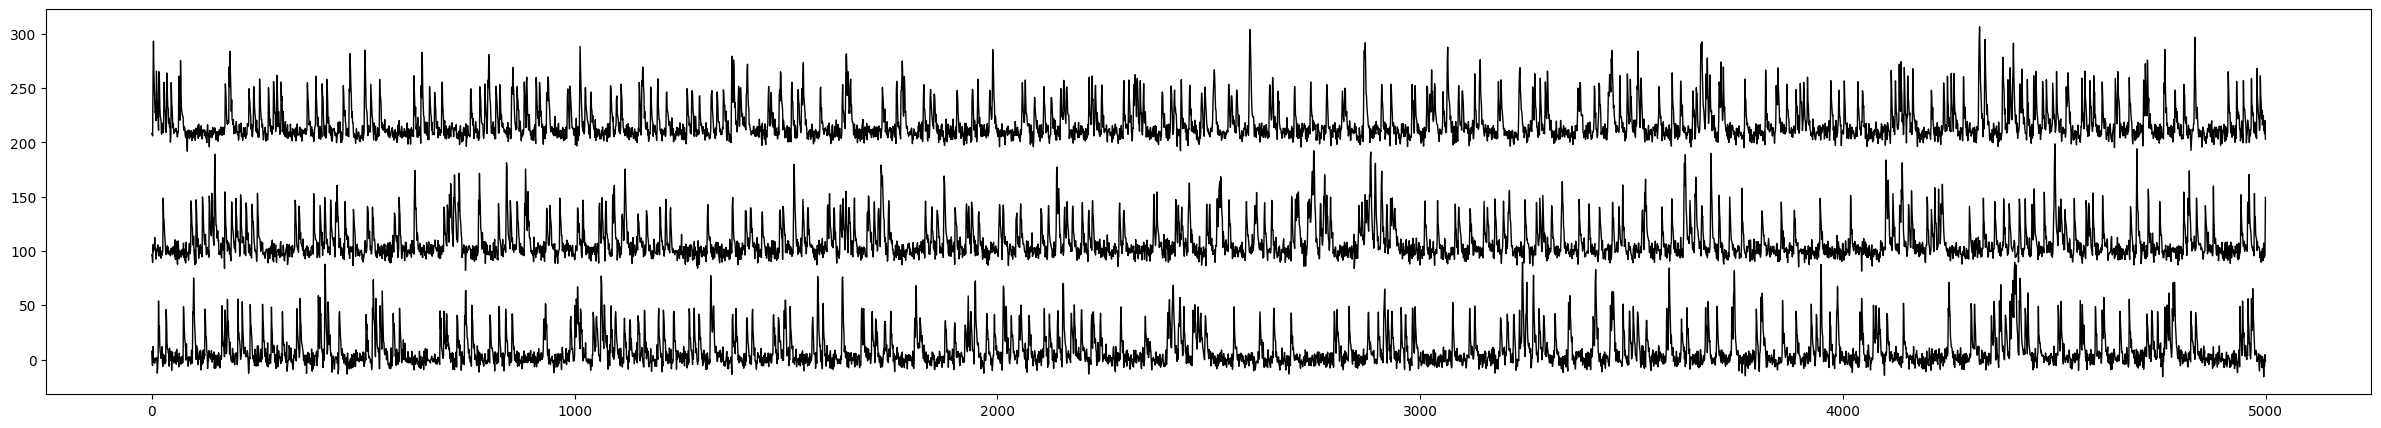

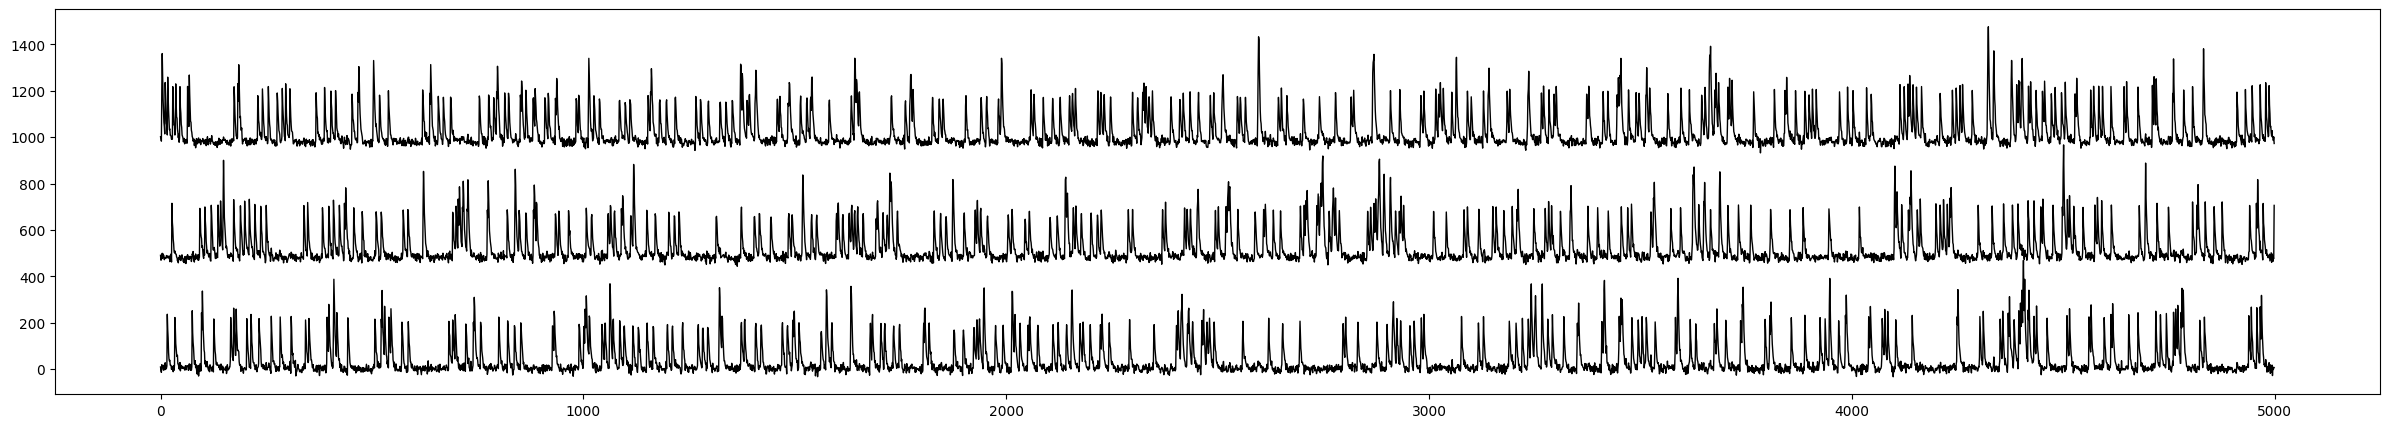

In [21]:
n = 1

plt.figure(figsize=(30, 5))

separation = 0
for i, x in enumerate(snmf_results[n]["X"].T[::5]):
    plt.plot(x + separation, linewidth=1, c="k")
    separation = x.max() + separation + 10

plt.show()

plt.figure(figsize=(30, 5))

separation = 0
for i, y in enumerate(snmf_results[n]["Y"]):
    plt.plot(y + separation, linewidth=1, c="k")
    separation = y.max() + separation + 10

plt.show()